# 13. Benchmark: resultados e inferencia estadística

En este capítulo comparamos los diez modelos profundos y los dos baselines no profundos sobre las 361 imágenes del conjunto de prueba, con 8 semillas por modelo. Presentamos la tabla principal, las pruebas globales y por pares, sus supuestos, las pruebas por imagen, la potencia del experimento y el análisis de eficiencia. La regla de decisión es la del capítulo 11: una diferencia es relevante si es significativa con la t pareada corregida por Holm sobre los 45 pares y su magnitud es al menos $\delta = 0.02$.

In [1]:
import sys, json
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "entregable2" / "src").exists())
E2 = ROOT / "entregable2"
for p in (E2 / "analisis", E2):
    if str(p) not in sys.path:
        sys.path.insert(0, str(p))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats as st
from IPython.display import display, Markdown
import figuras as FG
from comun import MODELS, E2_MODELS, MACHINE
FG.setup()
pd.set_option("display.precision", 4)
SUM = E2 / "results" / "summary"
COMP = E2 / "results" / "complementario"
mc = pd.read_csv(SUM / "metricas_por_corrida.csv")
w = pd.read_csv(SUM / "f1_macro_por_semilla.csv").set_index("seed")[MODELS]
bl = pd.read_csv(COMP / "baselines.csv")
glob = json.load(open(COMP / "estadistica_complementaria.json"))
eg = json.load(open(SUM / "estadistica_global.json"))

## 13.1 Tabla principal del benchmark

Para cada modelo reportamos:

- **F1 macro:** media ± DE sobre 8 semillas, con IC 95 % bootstrap sobre las semillas (10 000 remuestreos).
- **Calibración:** ECE de 15 bins.
- **Robustez:** índice de área bajo la curva de degradación con ruido gaussiano ($\sigma \in \{0, 0.05, 0.10\}$), normalizado por el F1 sin perturbar; vale 1 si el modelo no se degrada (sección 15.1).
- **Costo:** parámetros, GMAC por imagen y latencia por imagen en lote de 32, en la GPU indicada.
- **Rango promedio:** rango de Friedman, donde 1 es el mejor.

Los baselines trivial y clásico se describen en la sección 13.4.

In [2]:
rng = np.random.default_rng(0)
ri = pd.read_csv(COMP / "robustez_indice.csv").groupby("model").ir_ruido.mean()
g = mc.groupby("model")
rows = []
for m in MODELS:
    x = w[m].to_numpy()
    bs = x[rng.integers(0, 8, (10000, 8))].mean(1)
    rows.append({"modelo": m, "origen": "E1" if m in ("CNN", "MobileNetV2", "ResNet-18") else "E2",
                 "F1 macro": f"{x.mean():.3f} ± {x.std(ddof=1):.3f}",
                 "IC 95 % bootstrap": f"[{np.percentile(bs, 2.5):.3f}, {np.percentile(bs, 97.5):.3f}]",
                 "accuracy": g.accuracy.mean()[m], "bal. acc.": g.balanced_accuracy.mean()[m], "MCC": g.mcc.mean()[m],
                 "AUC-ROC": g.auc_roc_macro.mean()[m], "ECE": g.ece.mean()[m], "índice robustez": ri[m],
                 "parámetros (M)": g.params.first()[m] / 1e6, "GMAC": g.gmacs.first()[m],
                 "ms/imagen": g.ms_per_image.mean()[m], "GPU": MACHINE[m],
                 "rango Friedman": glob["rangos_medios"][m]})
for name, sub in bl.groupby("model"):
    rows.append({"modelo": name, "origen": "baseline", "F1 macro": f"{sub.f1_macro.mean():.3f} ± {sub.f1_macro.std(ddof=1) if len(sub) > 1 else 0:.3f}",
                 "IC 95 % bootstrap": "—", "accuracy": sub.accuracy.mean(), "bal. acc.": sub.balanced_accuracy.mean(),
                 "MCC": sub.mcc.mean()})
tabla = pd.DataFrame(rows).set_index("modelo").sort_values("rango Friedman", na_position="last")
display(tabla.round(3))

,origen,F1 macro,IC 95 % bootstrap,accuracy,bal. acc.,MCC,AUC-ROC,ECE,índice robustez,parámetros (M),GMAC,ms/imagen,GPU,rango Friedman
modelo,,,,,,,,,,,,,,
RWCNet,E2,0.945 ± 0.010,"[0.938, 0.951]",0.952,0.951,0.941,0.997,0.027,0.694,25.604,4.589,2.283,RTX 4060,1.500
ViT-B16,E2,0.938 ± 0.014,"[0.930, 0.947]",0.944,0.935,0.931,0.995,0.042,0.950,85.803,17.563,0.459,A100,2.000
GFN,E2,0.921 ± 0.015,"[0.912, 0.931]",0.935,0.919,0.921,0.992,0.051,0.834,113.671,5.675,0.967,A100,3.250
Celik-HC,E2,0.914 ± 0.013,"[0.905, 0.923]",0.926,0.912,0.910,0.986,0.056,0.424,28.424,3.223,1.120,A100,3.750
ResMsCapsule,E2,0.899 ± 0.015,"[0.889, 0.909]",0.911,0.901,0.892,0.983,0.193,0.529,4.217,1.420,0.405,RTX 4060,4.750
MbXception,E2,0.861 ± 0.014,"[0.852, 0.869]",0.874,0.863,0.847,0.981,0.057,0.409,28.393,6.195,1.418,RTX 4060,6.500
ResNet-18,E1,0.863 ± 0.022,"[0.848, 0.876]",0.871,0.861,0.842,0.979,0.051,0.512,11.180,1.814,0.327,RTX 4060,6.500
CNN,E1,0.826 ± 0.022,"[0.811, 0.839]",0.849,0.846,0.817,0.973,0.060,0.402,1.175,2.587,0.677,RTX 4060,8.500
FocusRCNet,E2,0.811 ± 0.015,"[0.802, 0.822]",0.832,0.819,0.795,0.968,0.132,0.362,0.521,0.127,0.368,RTX 4060,9.125


La tabla completa de métricas secundarias por modelo (F1 ponderado, precisión y recall macro, AUC-PR, NLL, Brier, tiempos) está en `entregable2/results/summary/tabla_benchmark.csv`, y las métricas de cada corrida en `metricas_por_corrida.csv`. Los modelos del capítulo 4 no guardaron NLL ni Brier.

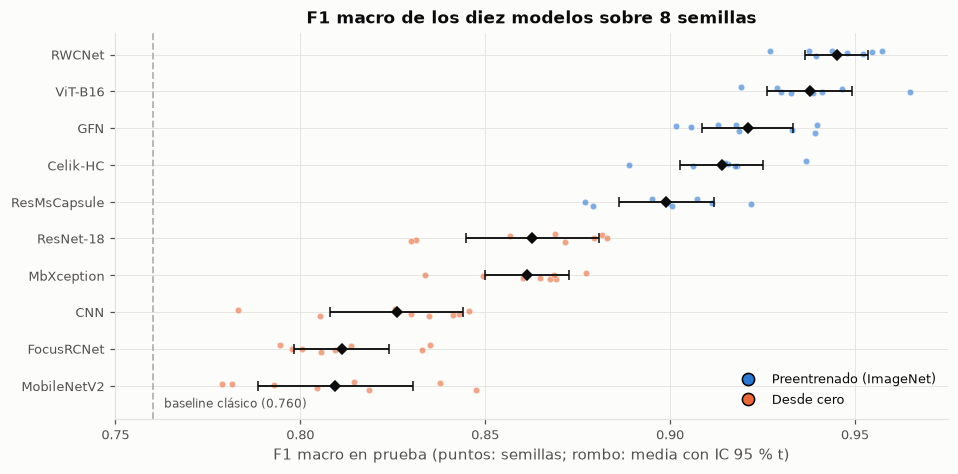

In [3]:
fig, ax = plt.subplots(figsize=(8.8, 4.4))
orden = w.mean().sort_values().index
for i, m in enumerate(orden):
    x = w[m].to_numpy()
    ax.scatter(x, np.full(8, i) + np.random.default_rng(i).uniform(-0.12, 0.12, 8), s=18, color=FG.color_regimen(m), alpha=0.6,
               edgecolor=FG.SURFACE, lw=0.5, zorder=3)
    h = st.t.ppf(0.975, 7) * x.std(ddof=1) / np.sqrt(8)
    ax.errorbar(x.mean(), i, xerr=h, fmt="D", color=FG.INK, ms=5, capsize=3, lw=1.2, zorder=4)
for name, sub in bl.groupby("model"):
    if "Hist" in name:
        ax.axvline(sub.f1_macro.mean(), color=FG.NEUTRAL, lw=1.2, ls="--")
        ax.text(sub.f1_macro.mean() + 0.003, -0.6, "baseline clásico (0.760)", fontsize=8, color=FG.INK2)
ax.set_yticks(range(len(orden)), orden); ax.set_ylim(-0.9, len(orden) - 0.4)
ax.set_xlabel("F1 macro en prueba (puntos: semillas; rombo: media con IC 95 % t)")
ax.set_title("F1 macro de los diez modelos sobre 8 semillas")
FG.leyenda_regimen(ax, loc="lower right"); plt.tight_layout(); plt.show()

## 13.2 Resultados de cada modelo

La tabla reúne, para cada modelo, la media ± DE sobre las 8 semillas de las métricas de prueba, la convergencia del entrenamiento y la comparación con el valor publicado. Después de la tabla, cada modelo se discute en orden de desempeño.

In [4]:
from comun import CLASSES, run_dir, load_pickle, SEEDS
ficha = []
pub = {"Celik-HC": 0.9940, "MbXception": 0.9434, "ViT-B16": 0.9698, "GFN": 0.9421, "FocusRCNet": 0.92, "ResMsCapsule": 0.9141, "RWCNet": 0.9501}
cmats, errores = {}, {}
for m in MODELS:
    cm = sum(np.asarray(load_pickle(run_dir(m, s) / "metrics_test.pkl")["confusion_matrix"]) for s in SEEDS)
    cmats[m] = cm
    off = cm.copy(); np.fill_diagonal(off, 0)
    i, j = np.unravel_index(off.argmax(), off.shape)
    errores[m] = (CLASSES[i], CLASSES[j], int(off[i, j]), int(off.sum()))
for m in orden[::-1]:
    d = mc[mc.model == m]
    f = lambda c: f"{d[c].mean():.3f} ± {d[c].std(ddof=1):.3f}" if d[c].notna().all() else "—"
    ficha.append({"modelo": m, "F1 macro": f("f1_macro"), "accuracy": f("accuracy"), "bal. accuracy": f("balanced_accuracy"),
                  "F1 ponderado": f("f1_weighted"), "precisión macro": f("precision_macro"), "recall macro": f("recall_macro"),
                  "MCC": f("mcc"), "AUC-ROC": f("auc_roc_macro"), "AUC-PR": f("auc_pr_macro"), "ECE": f("ece"), "NLL": f("nll"),
                  "errores por semilla (de 361)": f"{errores[m][3] / 8:.1f}",
                  "confusión dominante": f"{errores[m][0]} → {errores[m][1]} ({errores[m][2]})",
                  "mejor época / épocas": f"{d.best_epoch.mean():.0f} / {d.epochs_run.mean():.0f}",
                  "accuracy publicada": f"{100 * pub[m]:.2f} %" if m in pub else "— (modelo base)"})
display(pd.DataFrame(ficha).set_index("modelo").T)

modelo,RWCNet,ViT-B16,GFN,Celik-HC,ResMsCapsule,ResNet-18,MbXception,CNN,FocusRCNet,MobileNetV2
F1 macro,0.945 ± 0.010,0.938 ± 0.014,0.921 ± 0.015,0.914 ± 0.013,0.899 ± 0.015,0.863 ± 0.022,0.861 ± 0.014,0.826 ± 0.022,0.811 ± 0.015,0.809 ± 0.025
accuracy,0.952 ± 0.007,0.944 ± 0.011,0.935 ± 0.011,0.926 ± 0.010,0.911 ± 0.012,0.871 ± 0.018,0.874 ± 0.013,0.849 ± 0.026,0.832 ± 0.011,0.828 ± 0.020
bal. accuracy,0.951 ± 0.012,0.935 ± 0.016,0.919 ± 0.018,0.912 ± 0.011,0.901 ± 0.013,0.861 ± 0.018,0.863 ± 0.015,0.846 ± 0.015,0.819 ± 0.012,0.814 ± 0.023
F1 ponderado,0.952 ± 0.007,0.943 ± 0.011,0.934 ± 0.011,0.926 ± 0.010,0.911 ± 0.012,0.871 ± 0.018,0.873 ± 0.013,0.852 ± 0.026,0.832 ± 0.011,0.828 ± 0.019
precisión macro,0.942 ± 0.011,0.942 ± 0.014,0.927 ± 0.015,0.922 ± 0.023,0.900 ± 0.017,0.870 ± 0.027,0.866 ± 0.012,0.821 ± 0.021,0.811 ± 0.019,0.810 ± 0.029
recall macro,0.951 ± 0.012,0.935 ± 0.016,0.919 ± 0.018,0.912 ± 0.011,0.901 ± 0.013,0.861 ± 0.018,0.863 ± 0.015,0.846 ± 0.015,0.819 ± 0.012,0.814 ± 0.023
MCC,0.941 ± 0.009,0.931 ± 0.014,0.921 ± 0.013,0.910 ± 0.012,0.892 ± 0.014,0.842 ± 0.021,0.847 ± 0.016,0.817 ± 0.029,0.795 ± 0.014,0.789 ± 0.024
AUC-ROC,0.997 ± 0.001,0.995 ± 0.001,0.992 ± 0.002,0.986 ± 0.003,0.983 ± 0.004,0.979 ± 0.003,0.981 ± 0.002,0.973 ± 0.005,0.968 ± 0.002,0.968 ± 0.004
AUC-PR,0.983 ± 0.005,0.982 ± 0.005,0.966 ± 0.006,0.948 ± 0.010,0.947 ± 0.014,0.925 ± 0.010,0.931 ± 0.007,0.893 ± 0.015,0.887 ± 0.011,0.889 ± 0.013
ECE,0.027 ± 0.009,0.042 ± 0.010,0.051 ± 0.006,0.056 ± 0.012,0.193 ± 0.028,0.051 ± 0.009,0.057 ± 0.008,0.060 ± 0.008,0.132 ± 0.011,0.070 ± 0.012


### 13.2.1 RWCNet

RWCNet obtiene el mayor F1 macro del benchmark: 0.945 ± 0.010, con IC 95 % [0.938, 0.951]. Es también el primero en accuracy (0.952), accuracy balanceada (0.951), MCC (0.941), AUC-ROC (0.997) y AUC-PR (0.983). Comete el menor número de errores, 17 de 361 imágenes por semilla en promedio, y su confusión dominante es la de plástico clasificado como vidrio.

- **Por clase:** es el mejor en vidrio y plástico, las dos clases que más confunden los demás modelos, y alcanza un F1 de 0.89 en `trash`, con el mayor recall en esa clase (0.94).
- **Calibración:** es el modelo mejor calibrado sin ajuste (ECE de 0.027, NLL de 0.175).
- **Convergencia:** llega a su mejor época en promedio en la 20 y se detiene por paciencia hacia la 33.
- **Comparación con su artículo:** su accuracy (95.2 %) reproduce la publicada (95.01 %).
- **Componentes:** su ablación muestra que la rama DenseNet201 aporta 0.033 de F1 y la supervisión profunda 0.022, mientras que la rama MobileNetV2 no tiene un aporte significativo (sección 15.5).
- **Costo:** 25.6 M de parámetros y 4.6 GMAC por imagen. Es el modelo más lento por imagen de los entrenados en la RTX 4060 y el que más memoria usa en entrenamiento (4.9 GB).
- **Robustez:** pierde 0.30 de F1 con ruido gaussiano $\sigma = 0.05$, menos que cualquier otra CNN.

### 13.2.2 ViT-B16

ViT-B16 es el segundo modelo, con F1 de 0.938 ± 0.014 (IC [0.930, 0.947]), equivalente a RWCNet dentro de $\pm\delta$ (sección 13.8). Tiene el mejor F1 en cartón (0.98) y en `trash` (0.89), y la segunda mejor AUC-PR (0.982). Comete 20 errores por semilla, con la misma confusión dominante que RWCNet.

- **Robustez:** es su rasgo distintivo. Es el modelo menos afectado por el ruido, el desenfoque y el cambio de fondo (sección 15.1), y el que menos se correlaciona con los errores de las CNN, porque se equivoca en imágenes distintas.
- **Convergencia:** con la menor tasa de aprendizaje de la malla (3e-5), alcanza su mejor época hacia la 24 y entrena en 3.5 minutos por corrida en la A100.
- **Generalización:** su F1 de validación supera al de prueba en 0.030, con un IC que excluye el cero (sección 14.2).
- **Interpretabilidad:** sus mapas de Grad-CAM son los menos estables entre semillas.
- **Costo:** es el mayor del benchmark en operaciones (17.6 GMAC, 85.8 M de parámetros).
- **Comparación con su artículo:** su accuracy (94.4 %) queda 2.6 puntos por debajo de la publicada (96.98 %).

### 13.2.3 GFN

GFN alcanza un F1 de 0.921 ± 0.015 (IC [0.912, 0.931]) y es equivalente a Celik-HC dentro de $\pm\delta$ (TOST $p = 0.014$). Es el segundo mejor en plástico (0.93), y su principal fuente de error sigue siendo plástico clasificado como vidrio. Comete 23.5 errores por semilla.

- **Robustez:** su codificador Transformer le da el segundo índice de robustez al ruido (0.83), muy por encima de las CNN.
- **Generalización:** como ViT-B16, muestra un F1 de validación significativamente mayor que el de prueba (0.033).
- **Costo:** con 113.7 M de parámetros es el modelo más grande del benchmark, y queda dominado por RWCNet en la frontera de Pareto.
- **Comparación con su artículo:** su accuracy (93.5 %) está a 0.7 puntos de la publicada (94.21 %), una de las réplicas más cercanas.

### 13.2.4 Celik-HC (paper guía)

Celik-HC obtiene un F1 de 0.914 ± 0.013 (IC [0.905, 0.923]) y supera al modelo de referencia por 0.051. Es el mejor del benchmark en metal (0.95) y comete 27 errores por semilla, de nuevo con plástico clasificado como vidrio como confusión dominante.

- **Clasificador:** su salida oficial viene de XGBoost. La cabeza *softmax* de la misma red da un F1 de 0.924, mayor que el de XGBoost (sección 12.5).
- **Calibración:** su ECE (0.056) no se puede reducir con escalado de temperatura, porque las probabilidades vienen de XGBoost.
- **Robustez:** frente al cambio de fondo es robusto (pierde 0.04), pero colapsa con ruido gaussiano (de 0.914 a 0.255), la limitación que analiza el capítulo 12.
- **Costo:** con 28.4 M de parámetros y 3.2 GMAC es el modelo con mejor relación entre mejora y costo frente a ResNet-18.
- **Comparación con su artículo:** su accuracy (92.6 %) queda 6.8 puntos por debajo de la publicada (99.40 %).

### 13.2.5 ResMsCapsule

ResMsCapsule obtiene un F1 de 0.899 ± 0.015 (IC [0.889, 0.909]), 0.036 por encima de ResNet-18, una diferencia significativa dentro de la subfamilia de 7 contrastes pero no con la familia completa de 45 (sección 13.7). Tiene el patrón de errores más distinto: su confusión dominante es vidrio clasificado como metal (44 casos en 8 semillas), mientras que en los demás modelos es plástico clasificado como vidrio. Comete 32 errores por semilla.

- **Calibración:** sus probabilidades son las peor calibradas del benchmark (ECE de 0.193). Las longitudes de sus cápsulas son subconfiadas, y el escalado de temperatura ($T = 0.51$) corrige esa subconfianza hasta un ECE de 0.028.
- **Sobreajuste:** su brecha entre entrenamiento y validación (0.057) supera el margen $\delta_g$.
- **Costo:** con 4.2 M de parámetros y 1.4 GMAC está en la frontera de Pareto, y es el modelo más eficiente entre los que superan 0.89 de F1.
- **Comparación con su artículo:** su accuracy con seis clases (91.1 %) es cercana a la publicada con cuatro (91.41 %).

### 13.2.6 ResNet-18 (modelo de referencia)

El modelo de referencia del capítulo 7, entrenado desde cero, obtiene un F1 de 0.863 ± 0.022 (IC [0.848, 0.876]). Comete 46.5 errores por semilla; su confusión dominante es plástico clasificado como vidrio (55 casos) y su recall en `trash` es de 0.76.

- **Convergencia:** entrenado hasta 100 épocas, alcanza su mejor época cerca del final (86.8 en promedio).
- **Robustez:** pierde 0.47 de F1 con ruido gaussiano y 0.26 con el fondo sustituido, la caída por fondo más alta junto con la CNN.

La comparación con los modelos publicados muestra que la brecha frente a los modelos preentrenados (0.051 a 0.082) se concentra en `trash`, plástico y vidrio.

### 13.2.7 MbXception

MbXception, entrenado desde cero con su arquitectura de 8 ramas, obtiene un F1 de 0.861 ± 0.014 (IC [0.852, 0.869]), indistinguible de ResNet-18 (diferencia de −0.002). Su clase más débil es plástico, con recall de 0.74 y 68 imágenes confundidas con vidrio en 8 semillas. Comete 45.5 errores por semilla.

- **Convergencia:** alcanza su mejor época en la 51 de un máximo de 60, y 6 de sus 8 semillas llegan al tope de épocas.
- **Sobreajuste:** su brecha entre entrenamiento y validación es la mayor del benchmark (0.078).
- **Costo:** con 28.4 M de parámetros y 6.2 GMAC queda dominado en la frontera de Pareto.
- **Comparación con su artículo:** su accuracy (87.4 %) queda 6.9 puntos por debajo de la publicada (94.34 %). La entrada de 224 en lugar de 229 píxeles y el presupuesto de épocas son explicaciones plausibles.

### 13.2.8 CNN estilo VGG reducida

La CNN del capítulo 4 obtiene un F1 de 0.826 ± 0.022 (IC [0.811, 0.839]). Tiene un patrón de error propio: su confusión dominante es papel clasificado como `trash` (79 casos en 8 semillas), lo que reduce su precisión en `trash` a 0.50. Comete 54.5 errores por semilla. Su brecha entre entrenamiento y validación es la menor (0.011), un modelo con poca capacidad que no sobreajusta.

### 13.2.9 FocusRCNet

FocusRCNet obtiene un F1 de 0.811 ± 0.015 (IC [0.802, 0.822]), significativa y relevantemente por debajo de ResNet-18 (−0.052). Su confusión dominante es plástico clasificado como papel (55 casos), y su recall en plástico (0.69) y su precisión en `trash` (0.59) son los más bajos entre los modelos publicados. Comete 60.5 errores por semilla.

- **Convergencia:** las 8 semillas llegan al tope de 60 épocas.
- **Calibración:** la destilación con temperatura 4 sobresuaviza sus probabilidades (ECE de 0.132, $T = 3.2$).
- **Costo:** con 0.52 M de parámetros y 0.13 GMAC es el modelo más liviano y ocupa el extremo de la frontera de Pareto.
- **Comparación con su artículo:** su accuracy (83.2 %) queda 8.8 puntos por debajo de la publicada (~92 %), que se midió sobre el conjunto de validación y con entrada de 380 píxeles.

### 13.2.10 MobileNetV2

MobileNetV2, entrenada desde cero en el capítulo 4, obtiene el menor F1 (0.809 ± 0.025, IC [0.793, 0.826]) y la mayor dispersión entre semillas. Comete 62 errores por semilla, con plástico clasificado como vidrio (72 casos) como confusión dominante y un recall de 0.68 en `trash`. Con 2.2 M de parámetros y 0.30 GMAC es el segundo modelo más liviano.

## 13.3 Matrices de confusión y desempeño por clase

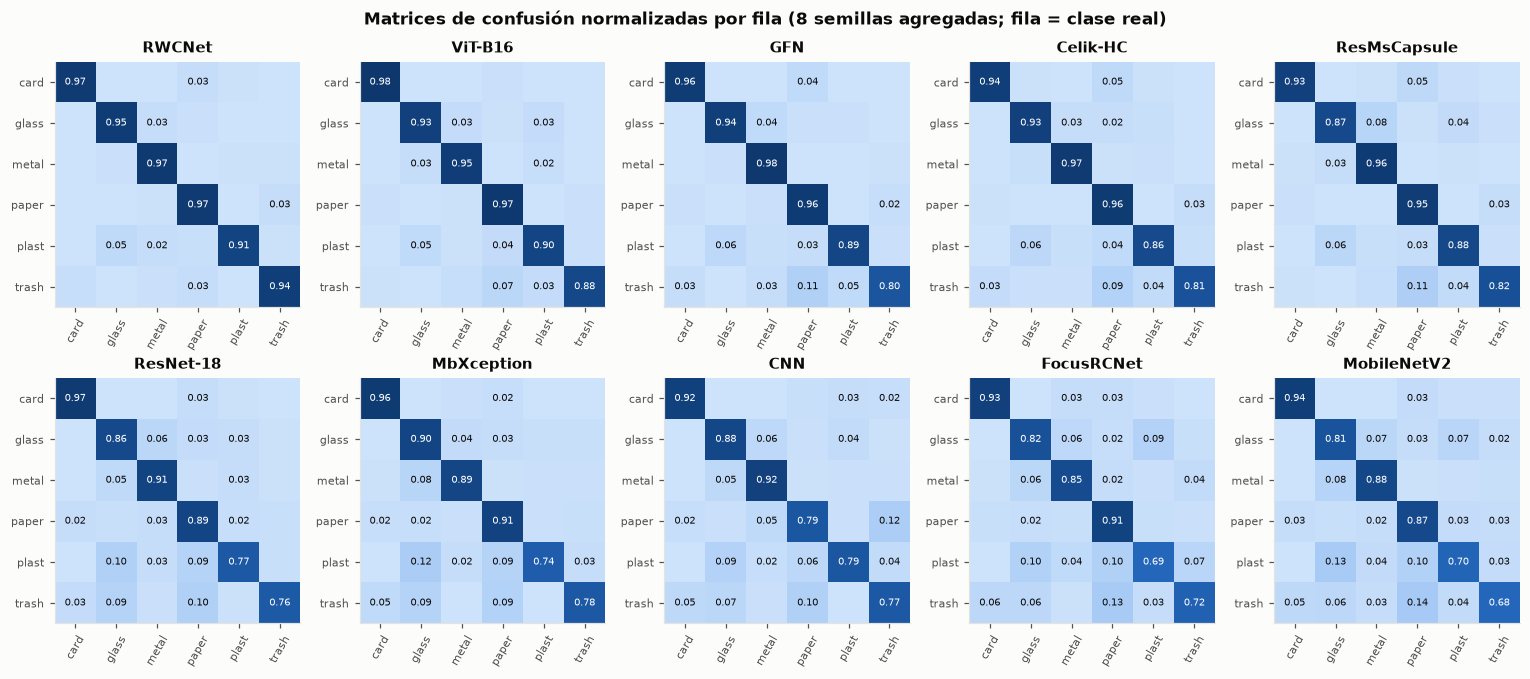

In [5]:
fig, axes = plt.subplots(2, 5, figsize=(14, 6.2))
from matplotlib.colors import LinearSegmentedColormap
cmap = LinearSegmentedColormap.from_list("seq", FG.SEQ)
ab = ["card", "glass", "metal", "paper", "plast", "trash"]
for ax, m in zip(axes.ravel(), orden[::-1]):
    cm = cmats[m] / cmats[m].sum(1, keepdims=True)
    ax.imshow(cm, cmap=cmap, vmin=0, vmax=1)
    for i in range(6):
        for j in range(6):
            if cm[i, j] >= 0.02:
                ax.text(j, i, f"{cm[i, j]:.2f}", ha="center", va="center", fontsize=6.5, color="white" if cm[i, j] > 0.6 else FG.INK)
    ax.set_title(m, fontsize=9.5); ax.set_xticks(range(6), ab, rotation=60, fontsize=7); ax.set_yticks(range(6), ab, fontsize=7); ax.grid(False)
fig.suptitle("Matrices de confusión normalizadas por fila (8 semillas agregadas; fila = clase real)", fontsize=11, fontweight="bold")
plt.tight_layout(); plt.show()

In [6]:
pr = []
for m in orden[::-1]:
    cm = cmats[m]
    rec, prec = np.diag(cm) / cm.sum(1), np.diag(cm) / cm.sum(0)
    for k, c in enumerate(CLASSES):
        pr.append({"modelo": m, "clase": c, "precisión": prec[k], "recall": rec[k]})
pr = pd.DataFrame(pr)
display(pr.pivot(index="modelo", columns="clase", values=["precisión", "recall"]).loc[orden[::-1]].round(2))

precisión                                    recall              \
clase        cardboard glass metal paper plastic trash cardboard glass metal   
modelo                                                                         
RWCNet            0.99  0.94  0.93  0.95    0.99  0.85      0.97  0.95  0.97   
ViT-B16           0.98  0.93  0.94  0.94    0.94  0.91      0.98  0.93  0.95   
GFN               0.98  0.93  0.91  0.92    0.97  0.84      0.96  0.94  0.98   
Celik-HC          0.98  0.92  0.94  0.90    0.95  0.81      0.94  0.93  0.97   
ResMsCapsule      0.97  0.91  0.88  0.91    0.93  0.78      0.93  0.87  0.96   
ResNet-18         0.96  0.83  0.85  0.86    0.90  0.80      0.97  0.86  0.91   
MbXception        0.95  0.80  0.89  0.87    0.94  0.74      0.96  0.90  0.89   
CNN               0.95  0.85  0.84  0.89    0.89  0.50      0.92  0.88  0.92   
FocusRCNet        0.95  0.82  0.82  0.85    0.83  0.59      0.93  0.82  0.85   
MobileNetV2       0.93  0.78  0.84  0.85    0.83  0.62      0.94  0.81  0.88   

                                  
clase        paper plastic trash  
modelo                            
RWCNet        0.97    0.91  0.94  
ViT-B16       0.98    0.90  0.88  
GFN           0.96    0.89  0.80  
Celik-HC      0.96    0.86  0.81  
ResMsCapsule  0.95    0.88  0.82  
ResNet-18     0.89    0.77  0.76  
MbXception    0.91    0.74  0.78  
CNN           0.79    0.79  0.77  
FocusRCNet    0.91    0.69  0.72  
MobileNetV2   0.87    0.70  0.68

Las matrices muestran tres patrones de error comunes a los diez modelos:

- **Plástico y vidrio:** se confunden en ambos sentidos, porque comparten transparencia y brillo. Es la confusión dominante en siete modelos.
- **Papel, cartón y `trash`:** se mezclan sobre todo en los modelos entrenados desde cero. La CNN y FocusRCNet envían papel y plástico a `trash` o a papel.
- **Metal y vidrio:** se confunden con objetos reflectantes, el patrón distintivo de ResMsCapsule.

El preentrenamiento reduce los tres patrones de forma pareja. La precisión en `trash` pasa de 0.50–0.80 en los modelos entrenados desde cero a 0.78–0.91 en los preentrenados. El recall en plástico pasa de 0.69–0.79 a 0.86–0.91. Cartón es la clase con mayor F1 en los diez modelos, con precisión entre 0.93 y 0.99 y recall entre 0.92 y 0.98.

## 13.4 Baselines no profundos

- **Baseline trivial:** predice siempre `paper`, la clase mayoritaria del entrenamiento.
- **Baseline clásico:** *gradient boosting* (`HistGradientBoostingClassifier`) sobre 390 descriptores manuales por imagen:
  - histogramas HSV;
  - media y desviación estándar RGB;
  - histogramas de orientación del gradiente en una malla de 4×4 (tipo HOG);
  - una miniatura en escala de grises.

El baseline clásico recibió el mismo presupuesto de ajuste que los modelos profundos: 8 configuraciones (tasa {0.1, 0.05} × hojas {15, 31} × regularización L2 {0, 1}), semilla 100, selección por F1 macro de validación y 8 semillas finales (`entregable2/analisis/baselines.py`). Sin submuestreo ni parada temprana, el algoritmo es determinista: sus 8 semillas dan el mismo resultado y su varianza entre semillas es nula.

In [7]:
bh = pd.read_csv(COMP / "baseline_clasico_busqueda.csv")
display(bh.round(4))
triv = bl[bl.model.str.startswith("Trivial")].iloc[0]
clas = bl[bl.model.str.startswith("Hist")].f1_macro.mean()
filas = []
for m in MODELS:
    x = w[m].to_numpy()
    for nombre, ref in [("clásico", clas), ("trivial", triv.f1_macro)]:
        t = st.ttest_1samp(x - ref, 0, alternative="greater")
        filas.append({"modelo": m, "frente a": nombre, "diferencia": x.mean() - ref, "p unilateral": t.pvalue})
cmp_ = pd.DataFrame(filas)
from statsmodels.stats.multitest import multipletests
cmp_["p Holm (20)"] = multipletests(cmp_["p unilateral"], method="holm")[1]
cmp_["> δ y significativa"] = (cmp_.diferencia >= 0.02) & (cmp_["p Holm (20)"] < 0.05)
display(cmp_.pivot(index="modelo", columns="frente a", values=["diferencia", "p Holm (20)"]).loc[MODELS].round(5))
print("Todos los modelos superan a ambos baselines con diferencia ≥ δ y p Holm < 0.05:", bool(cmp_["> δ y significativa"].all()))

,trial,learning_rate,max_leaf_nodes,l2_regularization,val_f1_macro
0,0,0.10,15,0.0,0.7873
1,1,0.10,15,1.0,0.7908
2,2,0.10,31,0.0,0.7930
3,3,0.10,31,1.0,0.7732
4,4,0.05,15,0.0,0.7964
5,5,0.05,15,1.0,0.7715
6,6,0.05,31,0.0,0.7788
7,7,0.05,31,1.0,0.7843


diferencia         p Holm (20)        
frente a        clásico trivial     clásico trivial
modelo                                             
Celik-HC         0.1538  0.8504  0.0000e+00     0.0
MbXception       0.1012  0.7978  0.0000e+00     0.0
ViT-B16          0.1776  0.8743  0.0000e+00     0.0
GFN              0.1609  0.8575  0.0000e+00     0.0
FocusRCNet       0.0510  0.7476  5.0000e-05     0.0
ResMsCapsule     0.1388  0.8355  0.0000e+00     0.0
RWCNet           0.1849  0.8815  0.0000e+00     0.0
CNN              0.0659  0.7625  5.0000e-05     0.0
MobileNetV2      0.0493  0.7460  4.2000e-04     0.0
ResNet-18        0.1027  0.7993  1.0000e-05     0.0

Todos los modelos superan a ambos baselines con diferencia ≥ δ y p Holm < 0.05: True


Los diez modelos profundos superan a los dos baselines. El peor de ellos (MobileNetV2, 0.809) aventaja al baseline clásico en 0.049, y el mejor (RWCNet) en 0.185. El baseline clásico confirma que la tarea no se resuelve con color y textura global, a pesar del atajo de fondo del capítulo 2. Su F1 de 0.760 es la ganancia mínima que debe justificar cualquier modelo profundo, y la diferencia entre el baseline clásico y el mejor modelo cuantifica el aporte real del Deep Learning en este problema.

## 13.5 Prueba global y supuestos

**Supuestos.**

- **Independencia:** cada semilla es una corrida independiente; dentro de una semilla, los diez modelos comparten la partición y el orden de los datos, por lo que las semillas actúan como bloques.
- **Normalidad:** se evalúa con Shapiro-Wilk (Shapiro y Wilk, 1965) sobre el F1 de cada modelo y sobre las diferencias pareadas.
- **Homocedasticidad:** se evalúa con Levene (centrado en la mediana).
- **Solapamiento del entrenamiento:** las 8 corridas de cada modelo usan la misma partición y solo varían la semilla (pesos iniciales, orden de lotes, aumento y *dropout*). No hay particiones repetidas con conjuntos de entrenamiento solapados, por lo que la corrección de Nadeau y Bengio (2003), que ajusta la varianza cuando los conjuntos de entrenamiento se solapan entre repeticiones, no aplica. La contrapartida es que la inferencia se refiere a este conjunto de prueba y a la variabilidad por semilla, no a la variabilidad por partición.

Como la potencia de estas pruebas es baja con 8 semillas, reportamos en paralelo una prueba paramétrica (ANOVA de medidas repetidas con corrección de Greenhouse-Geisser) y una no paramétrica (Friedman con $p$ por permutación y corrección de Iman-Davenport).

Para comparar varios clasificadores seguimos el procedimiento de Demšar (2006), la referencia habitual en aprendizaje automático: una prueba global de Friedman (1937) sobre los rangos dentro de cada bloque, que no supone normalidad, y comparaciones post hoc por pares con control de comparaciones múltiples. Usamos la corrección de Iman y Davenport (1980) porque el estadístico original de Friedman es conservador con pocos bloques. La corrección de Greenhouse y Geisser (1959) ajusta los grados de libertad del ANOVA de medidas repetidas cuando no se cumple la esfericidad. Con diez modelos y ocho semillas la esfericidad no se puede contrastar, porque la prueba de Mauchly necesita más bloques que niveles, así que aplicamos la corrección en todos los casos.

In [8]:
sh = pd.Series(glob["shapiro_p_por_modelo"]).rename("Shapiro-Wilk p")
display(sh.to_frame().T.round(3))
pp = pd.read_csv(SUM / "pruebas_pares.csv")
print(f"Levene (mediana): W = {glob['levene_W']:.3f}, p = {glob['levene_p']:.3f}")
print(f"Shapiro-Wilk sobre las 45 diferencias pareadas: {int((pp.shapiro_p_dif < 0.05).sum())} con p < 0.05 "
      f"(se esperan {0.05 * 45:.1f} por azar)")
gl = pd.DataFrame([
    ("Friedman (permutación, 100 000)", f"Q = {eg['friedman']['Q']:.2f}", f"p < {1/100001:.0e}", f"W de Kendall = {eg['friedman']['W_kendall']:.2f}"),
    ("Friedman con Iman-Davenport", f"F({glob['iman_davenport_gl'][0]}, {glob['iman_davenport_gl'][1]}) = {glob['iman_davenport_F']:.1f}",
     f"p = {max(glob['iman_davenport_p'], 1e-16):.1e}", ""),
    ("ANOVA de medidas repetidas (Greenhouse-Geisser)", f"F = {glob['anova_rm_F']:.1f}, ε = {glob['gg_epsilon']:.2f}",
     f"p = {glob['anova_rm_p_gg']:.1e}", f"η² parcial = {glob['eta2_parcial']:.2f}"),
    ("ANOVA de un factor sobre las 80 corridas", f"F = {eg['descomposicion_varianza']['F']:.1f}", f"p = {eg['descomposicion_varianza']['p']:.1e}",
     f"η² = {eg['descomposicion_varianza']['eta2']:.2f}; ICC(1) = {eg['descomposicion_varianza']['icc1']:.2f}"),
], columns=["prueba", "estadístico", "p", "tamaño de efecto"])
display(gl)

,Celik-HC,MbXception,ViT-B16,GFN,FocusRCNet,ResMsCapsule,RWCNet,CNN,MobileNetV2,ResNet-18
Shapiro-Wilk p,0.295,0.211,0.658,0.376,0.203,0.732,0.817,0.098,0.697,0.061


Levene (mediana): W = 0.965, p = 0.477
Shapiro-Wilk sobre las 45 diferencias pareadas: 3 con p < 0.05 (se esperan 2.2 por azar)


,prueba,estadístico,p,tamaño de efecto
0,"Friedman (permutación, 100 000)",Q = 64.77,p < 1e-05,W de Kendall = 0.90
1,Friedman con Iman-Davenport,"F(9, 63) = 62.7",p = 1.0e-16,
2,ANOVA de medidas repetidas (Greenhouse-Geisser),"F = 76.1, ε = 0.44",p = 2.1e-14,η² parcial = 0.92
3,ANOVA de un factor sobre las 80 corridas,F = 73.6,p = 4.0e-32,η² = 0.90; ICC(1) = 0.90


**RQ1.** Los diez modelos no tienen el mismo desempeño. Friedman rechaza la hipótesis nula ($p < 10^{-5}$) con un acuerdo muy alto entre semillas ($W = 0.90$), y la prueba paramétrica coincide. El modelo explica el 90 % de la varianza del F1 entre corridas y la semilla el 10 % restante, frente al 52 % del capítulo 5: al ampliar el rango de arquitecturas, la semilla pierde peso relativo. Ninguna prueba de normalidad por modelo rechaza al 5 %, y Levene no indica varianzas distintas, lo que respalda la t pareada como prueba de decisión.

## 13.6 Diagrama de diferencia crítica

El diagrama ordena los modelos por su rango medio (1 = mejor) y une con una barra los grupos cuya diferencia de rango es menor que la diferencia crítica de Nemenyi, tal como lo propone Demšar (2006):

$$\text{CD} = q_\alpha \sqrt{\frac{k(k+1)}{6N}} = 3.164\sqrt{\frac{10 \cdot 11}{6 \cdot 8}} = 4.79.$$

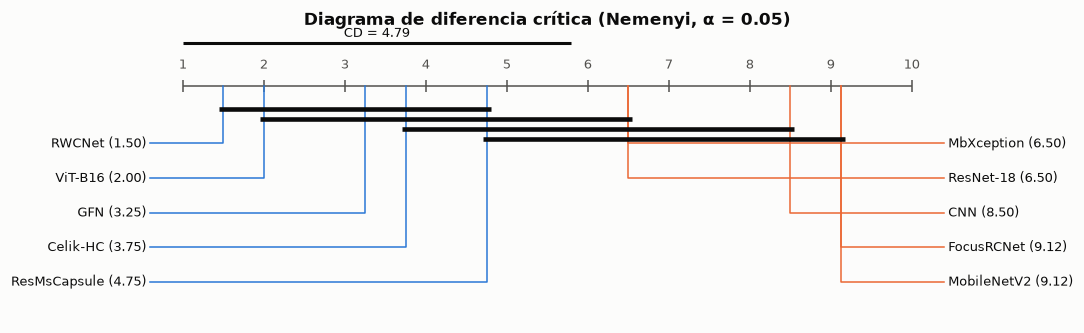

In [9]:
ranks = pd.Series(glob["rangos_medios"]).sort_values()
cd = glob["nemenyi_CD"]
fig, ax = plt.subplots(figsize=(9.5, 3.4))
ax.set_xlim(0.5, 10.5); ax.set_ylim(0, 1); ax.axis("off")
ax.hlines(0.82, 1, 10, color=FG.INK2, lw=1)
for k in range(1, 11):
    ax.vlines(k, 0.80, 0.84, color=FG.INK2, lw=1); ax.text(k, 0.88, str(k), ha="center", fontsize=8.5, color=FG.INK2)
ax.hlines(0.97, 1, 1 + cd, color=FG.INK, lw=2); ax.text(1 + cd / 2, 0.99, f"CD = {cd:.2f}", ha="center", fontsize=8.5)
items = list(ranks.items())
for i, (m, r) in enumerate(items):
    left = i < 5
    yy = 0.62 - (i if left else i - 5) * 0.12
    xt = 0.6 if left else 10.4
    ax.plot([r, r, xt], [0.82, yy, yy], color=FG.color_regimen(m), lw=1)
    ax.text(xt + (-0.05 if left else 0.05), yy, f"{m} ({r:.2f})", ha="right" if left else "left", va="center", fontsize=8.5)
# grupos no distinguibles: intervalos maximales con amplitud < CD
vals = ranks.values; grupos = []
for i in range(len(vals)):
    j = max(k for k in range(len(vals)) if vals[k] - vals[i] < cd)
    if j > i and not any(a <= i and j <= b for a, b in grupos):
        grupos.append((i, j))
for n, (i, j) in enumerate(grupos):
    y = 0.74 - n * 0.035
    ax.hlines(y, vals[i] - 0.05, vals[j] + 0.05, color=FG.INK, lw=3)
ax.set_title("Diagrama de diferencia crítica (Nemenyi, α = 0.05)")
plt.show()

Nemenyi es conservadora con 10 modelos y 8 bloques: solo separa pares con diferencias de rango mayores que 4.79. Por eso los grupos se solapan. RWCNet, ViT-B16, GFN, Celik-HC y ResMsCapsule no se distinguen entre sí por rangos, pero sí del grupo inferior (FocusRCNet, MobileNetV2 y CNN). Las comparaciones por pares de la sección 13.7 usan las diferencias de F1 y no solo los rangos, y tienen más potencia.

## 13.7 Contrastes confirmatorios

**RQ2: cada modelo publicado frente al modelo de referencia (ResNet-18).** Los 7 contrastes forman parte de la familia preregistrada de 45 pares, y el $p$ se ajusta por Holm (1979) sobre los 45. Elegimos Holm porque controla la probabilidad de cometer al menos un falso positivo en la familia, igual que Bonferroni, pero rechaza siempre al menos tanto como este. Como análisis de sensibilidad mostramos también el ajuste dentro de la subfamilia de 7. Cada contraste se evalúa con tres pruebas distintas:

1. t pareada, con normalidad verificada (prueba paramétrica pareada);
2. Wilcoxon de rangos con signo (Wilcoxon, 1945), no paramétrica;
3. Friedman con post hoc de Conover (Conover, 1999) y Holm (procedimiento global con control de comparaciones múltiples, sección 13.8).

Los IC bootstrap son percentiles sobre 10 000 remuestreos de las semillas (Efron y Tibshirani, 1993), y no suponen normalidad de las diferencias.

In [10]:
fam = pd.read_csv(COMP / "familia_vs_resnet18.csv")
con = pd.read_csv(SUM / "posthoc_conover_holm.csv").set_index("model")
fam["Conover-Holm p"] = [con.loc[m, "ResNet-18"] for m in fam.modelo]
fam["IC 95 % (t)"] = [f"[{a:.3f}, {b:.3f}]" for a, b in zip(fam.ic_t_lo, fam.ic_t_hi)]
fam["IC 95 % (bootstrap)"] = [f"[{a:.3f}, {b:.3f}]" for a, b in zip(fam.ic_boot_lo, fam.ic_boot_hi)]
fam["≥ 0.036 (umbral del cap. 7)"] = fam.dif >= 0.036
display(fam[["modelo", "dif", "IC 95 % (t)", "IC 95 % (bootstrap)", "d_z", "shapiro_p", "p_t", "p_t_holm_45", "p_t_holm_7",
             "p_wilcoxon", "Conover-Holm p", "≥ 0.036 (umbral del cap. 7)", "decision"]]
        .set_index("modelo").round(4))

,dif,IC 95 % (t),IC 95 % (bootstrap),d_z,shapiro_p,p_t,p_t_holm_45,p_t_holm_7,p_wilcoxon,Conover-Holm p,≥ 0.036 (umbral del cap. 7),decision
modelo,,,,,,,,,,,,
Celik-HC,0.0511,"[0.030, 0.073]","[0.034, 0.068]",1.9815,0.6705,0.0008,0.0154,0.0032,0.0078,0.0000,True,superior: significativa y relevante
MbXception,-0.0015,"[-0.021, 0.018]","[-0.017, 0.014]",-0.0629,0.9598,0.8637,1.0000,0.8637,0.8438,1.0000,False,no concluyente
ViT-B16,0.0750,"[0.051, 0.098]","[0.057, 0.094]",2.6688,0.3975,0.0001,0.0037,0.0008,0.0078,0.0000,True,superior: significativa y relevante
GFN,0.0582,"[0.032, 0.084]","[0.039, 0.079]",1.8673,0.3680,0.0011,0.0205,0.0034,0.0078,0.0000,True,superior: significativa y relevante
FocusRCNet,-0.0516,"[-0.072, -0.032]","[-0.068, -0.037]",-2.1678,0.5620,0.0005,0.0100,0.0024,0.0078,0.0001,False,inferior: significativa y relevante
ResMsCapsule,0.0362,"[0.011, 0.061]","[0.018, 0.055]",1.2179,0.6026,0.0108,0.1292,0.0215,0.0156,0.0147,True,no concluyente
RWCNet,0.0822,"[0.069, 0.095]","[0.072, 0.092]",5.2538,0.9892,0.0000,0.0001,0.0000,0.0078,0.0000,True,superior: significativa y relevante


**Respuesta a RQ2.** Cuatro modelos publicados superan al modelo de referencia del capítulo 7 por más del umbral de 0.036, con significancia tras Holm y con las tres pruebas en el mismo sentido:

| Modelo | Diferencia de F1 frente a ResNet-18 | $d_z$ | $p$ Holm (t) |
|---|---|---|---|
| RWCNet | +0.082 | 5.3 | < 0.001 |
| ViT-B16 | +0.075 | 2.7 | 0.004 |
| GFN | +0.058 | 1.9 | 0.021 |
| Celik-HC | +0.051 | 2.0 | 0.015 |

Los cuatro son preentrenados.

Los demás resultados son:

- **ResMsCapsule** supera a ResNet-18 en 0.036, pero no es significativo con Holm sobre los 45 pares ($p = 0.13$). Dentro de la subfamilia de 7 sí lo es ($p = 0.02$), por lo que el resultado depende de la familia elegida; según la regla preregistrada es no concluyente.
- **MbXception**, entrenado desde cero, no difiere de ResNet-18 (−0.002, $p = 1.0$). La diferencia no demuestra equivalencia.
- **FocusRCNet** es inferior a ResNet-18 (−0.052, $p$ Holm = 0.010).

Wilcoxon da $p = 0.0078$ en todos los contrastes con las 8 diferencias del mismo signo, el mínimo posible con $n = 8$. Tras Holm no alcanza significancia por la razón explicada en la sección 11.2.

**Las 45 comparaciones por pares.** La matriz resume todas las diferencias de F1 macro entre los diez modelos (fila menos columna, media de las 8 semillas). El asterisco marca los pares con una diferencia relevante y significativa según la regla preregistrada.

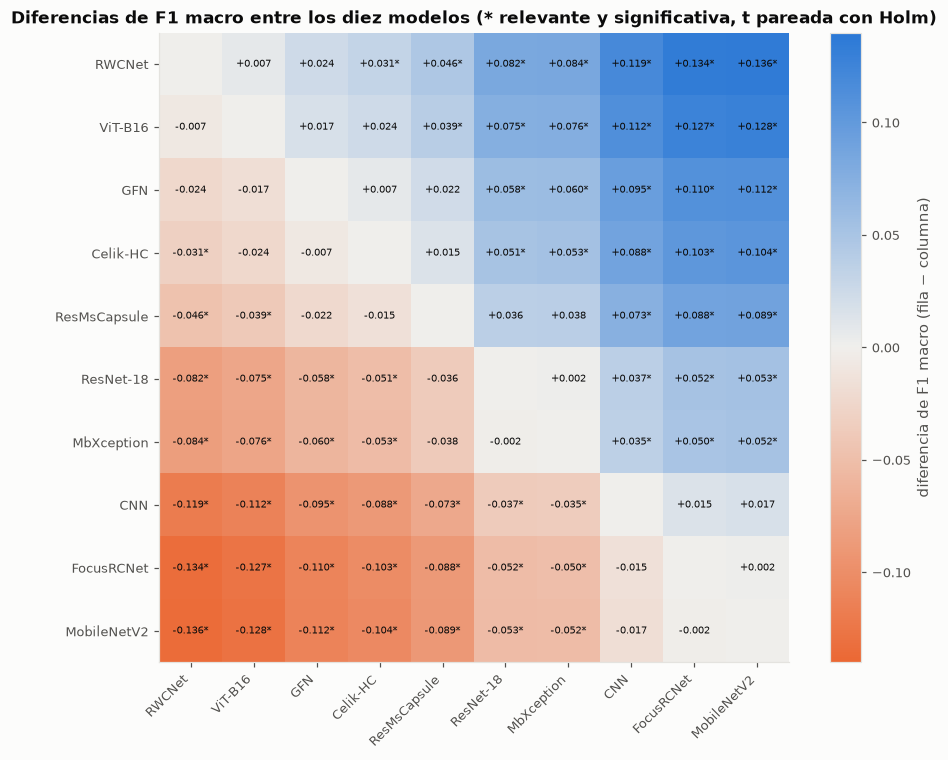

Pares relevantes y significativos: 32 de 45


In [11]:
ordm = orden[::-1]
D = pd.DataFrame(0.0, index=ordm, columns=ordm); Sg = pd.DataFrame("", index=ordm, columns=ordm)
for r in pp.itertuples():
    D.loc[r.A, r.B], D.loc[r.B, r.A] = r.dif_media, -r.dif_media
    if r.relevante_y_significativa:
        Sg.loc[r.A, r.B] = Sg.loc[r.B, r.A] = "*"
fig, ax = plt.subplots(figsize=(8.6, 7))
from matplotlib.colors import LinearSegmentedColormap
div = LinearSegmentedColormap.from_list("div", [FG.SERIES[1], "#f0efec", FG.SERIES[0]])
im = ax.imshow(D.to_numpy(), cmap=div, vmin=-0.14, vmax=0.14)
for i in range(10):
    for j in range(10):
        if i != j:
            ax.text(j, i, f"{D.iat[i, j]:+.3f}{Sg.iat[i, j]}", ha="center", va="center", fontsize=6.8, color=FG.INK)
ax.set_xticks(range(10), ordm, rotation=45, ha="right"); ax.set_yticks(range(10), ordm); ax.grid(False)
plt.colorbar(im, ax=ax, fraction=0.04, label="diferencia de F1 macro (fila − columna)")
ax.set_title("Diferencias de F1 macro entre los diez modelos (* relevante y significativa, t pareada con Holm)")
plt.tight_layout(); plt.show()
print(f"Pares relevantes y significativos: {int(pp.relevante_y_significativa.sum())} de 45")

## 13.8 Comparaciones entre los mejores modelos, equivalencia y sensibilidad

In [12]:
eq = pd.read_csv(COMP / "equivalencia_tost_rope.csv")
top = ["RWCNet", "ViT-B16", "GFN", "Celik-HC", "ResMsCapsule"]
e = eq[eq.A.isin(top) & eq.B.isin(top)].copy()
e = e.merge(pp[["A", "B", "p_t_holm"]], on=["A", "B"], how="left").merge(
    pp[["A", "B", "p_t_holm"]].rename(columns={"A": "B", "B": "A"}), on=["A", "B"], how="left", suffixes=("", "_r"))
e["p_t_holm"] = e.p_t_holm.fillna(e.p_t_holm_r)
e["Conover-Holm p"] = [con.loc[a, b] for a, b in zip(e.A, e.B)]
display(e[["A", "B", "dif_media", "ic90_lo", "ic90_hi", "p_t_holm", "Conover-Holm p", "p_tost", "p_bayes_A_peor", "p_bayes_rope",
           "p_bayes_A_mejor", "A12"]].sort_values("dif_media").round(3).reset_index(drop=True))

,A,B,dif_media,ic90_lo,ic90_hi,p_t_holm,Conover-Holm p,p_tost,p_bayes_A_peor,p_bayes_rope,p_bayes_A_mejor,A12
0,GFN,Celik-HC,0.007,-0.002,0.016,0.862,1.000,0.014,0.0,0.995,0.005,0.625
1,RWCNet,ViT-B16,0.007,-0.003,0.017,0.870,1.000,0.024,0.0,1.000,0.000,0.688
2,Celik-HC,ResMsCapsule,0.015,-0.000,0.030,0.755,0.389,0.278,0.0,0.882,0.118,0.781
3,ViT-B16,GFN,0.017,0.006,0.028,0.204,0.141,0.299,0.0,0.817,0.183,0.781
4,GFN,ResMsCapsule,0.022,0.008,0.036,0.187,0.043,0.606,0.0,0.616,0.384,0.859
5,ViT-B16,Celik-HC,0.024,0.010,0.038,0.151,0.015,0.693,0.0,0.334,0.666,0.938
6,RWCNet,GFN,0.024,0.009,0.039,0.184,0.015,0.686,0.0,0.480,0.520,0.906
7,RWCNet,Celik-HC,0.031,0.018,0.044,0.035,0.001,0.927,0.0,0.139,0.861,0.984
8,ViT-B16,ResMsCapsule,0.039,0.028,0.049,0.005,0.000,0.994,0.0,0.014,0.986,0.984
9,RWCNet,ResMsCapsule,0.046,0.034,0.058,0.005,0.000,0.997,0.0,0.003,0.997,1.000


Además de la diferencia y su $p$ ajustado, la tabla incluye tres medidas:

- **Equivalencia (TOST):** las dos pruebas unilaterales de Schuirmann (1987), con margen $\pm\delta$; el IC 90 % de la diferencia debe quedar dentro de $(-0.02, 0.02)$. A diferencia de una prueba de diferencias, su hipótesis nula es que los modelos difieren en al menos $\delta$, de modo que rechazarla permite afirmar equivalencia.
- **Prueba bayesiana de rangos con signo** (Benavoli et al., 2017): probabilidad de que A sea peor, equivalente dentro de la región de equivalencia práctica (ROPE $= \pm\delta$) o mejor. Benavoli et al. la proponen para comparar clasificadores porque, a diferencia del $p$ frecuentista, cuantifica directamente la probabilidad de equivalencia práctica, que una ausencia de significancia no permite afirmar.
- **Probabilidad de superioridad** $A_{12}$ (Vargha y Delaney, 2000): probabilidad de que una semilla de A supere a una de B. Es un tamaño de efecto no paramétrico que complementa a $d_z$ cuando la distribución no es normal.

Los resultados entre los mejores modelos son:

- **RWCNet frente a ViT-B16:** equivalentes en la práctica. La diferencia es de 0.007, TOST da $p = 0.024$ y la probabilidad bayesiana de la ROPE es 1.00. No hay un único modelo ganador: dos arquitecturas muy distintas, fusión de CNN y Transformer, alcanzan el mismo desempeño.
- **GFN frente a Celik-HC:** también equivalentes (diferencia de 0.007, TOST $p = 0.014$).
- **RWCNet frente a Celik-HC:** la única diferencia significativa y relevante entre los cinco mejores (0.031, $p$ Holm = 0.035).
- **ViT-B16 frente a Celik-HC y RWCNet frente a GFN:** la conclusión depende de la prueba. Conover-Holm las declara significativas y la t con Holm no; las clasificamos como no concluyentes.

In [13]:
sen = pd.read_csv(COMP / "sensibilidad_decision.csv")
res = pd.DataFrame({"prueba de decisión": ["t pareada + Holm (preregistrada)", "Wilcoxon + Holm", "IC bootstrap excluye 0",
                                           "Conover + Holm", "Nemenyi"],
                    "pares relevantes y significativos (de 45)": [int(sen[c].sum()) for c in
                                                                    ["t_holm", "wilcoxon_holm", "bootstrap_ic", "conover_holm", "nemenyi"]]})
display(res)
acuerdo = (sen.t_holm == sen.conover_holm).mean()
print(f"Acuerdo entre t-Holm y Conover-Holm en la decisión de los 45 pares: {100 * acuerdo:.0f} %")

,prueba de decisión,pares relevantes y significativos (de 45)
0,t pareada + Holm (preregistrada),32
1,Wilcoxon + Holm,0
2,IC bootstrap excluye 0,37
3,Conover + Holm,37
4,Nemenyi,13


Acuerdo entre t-Holm y Conover-Holm en la decisión de los 45 pares: 89 %


**Análisis de sensibilidad.** La conclusión principal (RQ2) se mantiene con la t pareada, el bootstrap y Conover. Wilcoxon con Holm no puede rechazar ningún par con 8 semillas, y Nemenyi es la prueba más conservadora. Las decisiones que cambian entre pruebas corresponden a diferencias cercanas a $\delta$, que reportamos como no concluyentes.

## 13.9 Pruebas por imagen: McNemar, Q de Cochran y DeLong

Las pruebas por imagen comparan modelos sobre el mismo conjunto de prueba dentro de cada semilla. McNemar (1947) compara dos modelos por las imágenes en que solo uno acierta; Dietterich (1998) la recomienda para comparar clasificadores evaluados sobre un mismo conjunto de prueba por su baja tasa de error tipo I. La Q de Cochran (1950) la extiende a los diez modelos, y la prueba de DeLong et al. (1988) compara AUC estimadas sobre las mismas imágenes, teniendo en cuenta su correlación. Su unidad de análisis es la imagen, por lo que su conclusión se refiere a este conjunto de prueba y no a la variabilidad entre entrenamientos.

In [14]:
mn = pd.read_csv(SUM / "mcnemar_por_semilla.csv")
mn["sig"] = mn.p_holm_semilla < 0.05
pares = [("RWCNet", "ViT-B16"), ("RWCNet", "GFN"), ("RWCNet", "Celik-HC"), ("ViT-B16", "Celik-HC"), ("RWCNet", "ResNet-18"),
         ("ViT-B16", "ResNet-18"), ("Celik-HC", "ResNet-18"), ("GFN", "ResNet-18")]
filas = []
for a, b in pares:
    s = mn[((mn.A == a) & (mn.B == b)) | ((mn.A == b) & (mn.B == a))]
    filas.append({"par": f"{a} – {b}", "semillas con McNemar significativo (Holm por semilla)": f"{int(s.sig.sum())} de 8",
                  "discordantes medios (b + c)": (s.b + s.c).mean()})
display(pd.DataFrame(filas))
cq = pd.read_csv(COMP / "cochran_q.csv")
print(f"Q de Cochran (10 modelos, por semilla): Q entre {cq.Q_cochran.min():.0f} y {cq.Q_cochran.max():.0f}, gl = 9, p < 1e-10 en las 8 semillas")
dl = pd.read_csv(COMP / "delong_ovr.csv")
dls = dl.groupby(["A", "B", "clase"]).agg(dif_AUC=("dif", "mean"), semillas_sig=("p_holm", lambda x: int((x < 0.05).sum()))).reset_index()
display(dls.pivot(index=["A", "B"], columns="clase", values="semillas_sig"))

,par,semillas con McNemar significativo (Holm por semilla),discordantes medios (b + c)
0,RWCNet – ViT-B16,0 de 8,21.000
1,RWCNet – GFN,0 de 8,19.625
2,RWCNet – Celik-HC,1 de 8,23.375
3,ViT-B16 – Celik-HC,0 de 8,28.375
4,RWCNet – ResNet-18,8 de 8,42.875
5,ViT-B16 – ResNet-18,5 de 8,47.625
6,Celik-HC – ResNet-18,2 de 8,48.250
7,GFN – ResNet-18,4 de 8,45.000


Q de Cochran (10 modelos, por semilla): Q entre 90 y 156, gl = 9, p < 1e-10 en las 8 semillas


clase               cardboard  glass  metal  paper  plastic  trash
A        B                                                        
Celik-HC ResNet-18          0      0      1      2        0      0
RWCNet   Celik-HC           0      0      0      0        0      0
         GFN                0      0      0      0        0      0
         ResNet-18          0      2      1      7        3      0
         ViT-B16            0      0      0      0        0      0
ViT-B16  GFN                0      0      0      0        0      0

**McNemar.** Entre RWCNet y ViT-B16, ninguna semilla muestra una diferencia significativa en la tasa de error. Frente a ResNet-18, RWCNet difiere en las 8 semillas, ViT-B16 en 5, GFN en 4 y Celik-HC en 2: con 361 imágenes, McNemar solo detecta de forma consistente las diferencias mayores.

**Q de Cochran.** Rechaza en las 8 semillas que los diez modelos tengan la misma proporción de aciertos.

**DeLong.** Comparamos las AUC uno contra todos por clase. Elegimos este esquema porque la AUC macro es un promedio de AUC binarias con muestras de positivos distintas. La tabla cuenta en cuántas semillas la diferencia de AUC es significativa tras Holm sobre las 6 clases. Las AUC están cerca del techo (≥ 0.98) y la prueba solo detecta diferencias frente a ResNet-18, sobre todo en `paper` (7 de 8 semillas para RWCNet) y `plastic` (3 de 8). Entre los mejores modelos no hay diferencias de AUC significativas en ninguna clase.

## 13.10 Potencia y diferencia mínima detectable

In [15]:
mde = pd.read_csv(SUM / "diferencia_minima_detectable.csv")
print(f"σ_d entre pares: mediana {mde.sd_d.median():.4f} (rango {mde.sd_d.min():.4f}–{mde.sd_d.max():.4f})")
print(f"MDE con 8 semillas y potencia 0.80: mediana {mde.MDE.median():.3f} (rango {mde.MDE.min():.3f}–{mde.MDE.max():.3f})")
print(f"Semillas necesarias para detectar δ = 0.02: mediana {mde.R_necesario.median():.0f} (rango {mde.R_necesario.min()}–{mde.R_necesario.max()}); "
      f"pares con R necesario ≤ 8: {(mde.R_necesario <= 8).sum()} de 45")
top_pairs = mde[mde.A.isin(top) & mde.B.isin(top)]
display(top_pairs.round(4))

σ_d entre pares: mediana 0.0226 (rango 0.0132–0.0367)
MDE con 8 semillas y potencia 0.80: mediana 0.022 (rango 0.013–0.036)
Semillas necesarias para detectar δ = 0.02: mediana 11 (rango 4–27); pares con R necesario ≤ 8: 14 de 45


,A,B,sd_d,n,MDE,R_necesario
1,Celik-HC,ViT-B16,0.0206,8,0.0204,9
2,Celik-HC,GFN,0.0132,8,0.0131,4
4,Celik-HC,ResMsCapsule,0.0230,8,0.0228,11
5,Celik-HC,RWCNet,0.0191,8,0.0189,8
17,ViT-B16,GFN,0.0167,8,0.0166,6
19,ViT-B16,ResMsCapsule,0.0158,8,0.0157,5
20,ViT-B16,RWCNet,0.0151,8,0.0150,5
25,GFN,ResMsCapsule,0.0210,8,0.0208,9
26,GFN,RWCNet,0.0222,8,0.0220,10
35,ResMsCapsule,RWCNet,0.0183,8,0.0181,7


Con 8 semillas, la diferencia mínima detectable con potencia de 0.80 tiene una mediana de 0.022, cercana a $\delta$, pero varía entre pares. Para los pares con más varianza (los que involucran a modelos entrenados desde cero) se necesitarían hasta 27 semillas. Entre los cinco mejores modelos, la MDE es menor que $\delta$ en la mayoría de los pares, por lo que la ausencia de significancia entre ellos es informativa y la complementamos con TOST y ROPE.

## 13.11 Eficiencia y frontera de Pareto

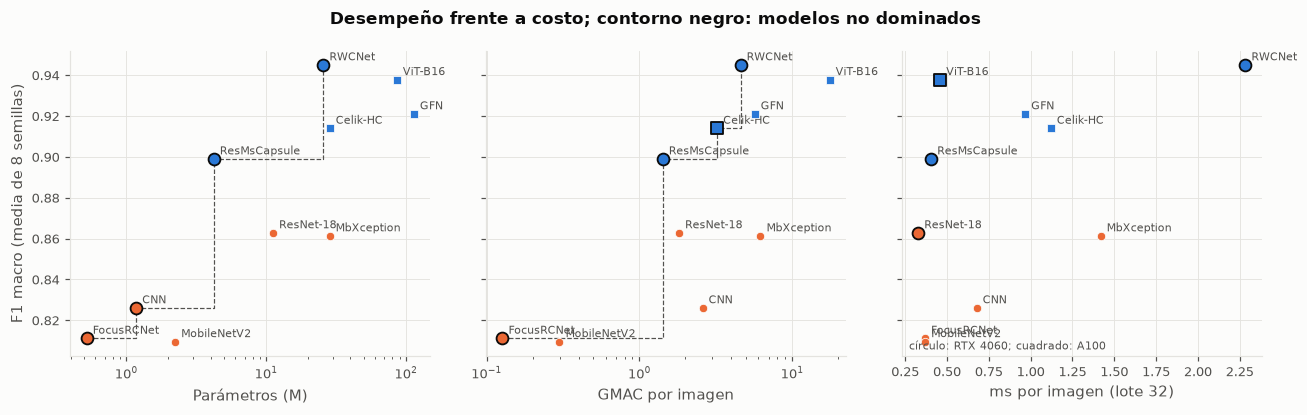

,f1,params,gmacs,ms_img,maquina,pareto_params,pareto_gmacs,pareto_latencia,eta_f1_por_gmac,eta_ic_lo,eta_ic_hi
model,,,,,,,,,,,
Celik-HC,0.9139,28424098,3.2230,1.1201,A100,False,True,False,0.0363,0.0243,0.0474
MbXception,0.8613,28393190,6.1948,1.4181,RTX 4060,False,False,False,-0.0003,-0.0039,0.0030
ViT-B16,0.9378,85803270,17.5631,0.4587,A100,False,False,True,0.0048,0.0037,0.0059
GFN,0.9210,113671336,5.6748,0.9667,A100,False,False,False,0.0151,0.0103,0.0204
FocusRCNet,0.8112,520630,0.1267,0.3680,RTX 4060,True,True,False,0.0306,0.0220,0.0398
ResMsCapsule,0.8990,4216896,1.4198,0.4048,RTX 4060,True,True,True,-0.0919,-0.1407,-0.0464
RWCNet,0.9450,25603986,4.5890,2.2830,RTX 4060,True,True,True,0.0296,0.0259,0.0332
CNN,0.8261,1174758,2.5867,0.6768,RTX 4060,True,False,False,-0.0475,-0.0644,-0.0277
MobileNetV2,0.8095,2231558,0.2995,0.3688,RTX 4060,False,False,False,0.0352,0.0233,0.0478


In [16]:
ef = pd.read_csv(COMP / "eficiencia_pareto.csv").set_index("model")
fig, axes = plt.subplots(1, 3, figsize=(12, 3.8), sharey=True)
for ax, (col, lab, logx) in zip(axes, [("params", "Parámetros (M)", True), ("gmacs", "GMAC por imagen", True), ("ms_img", "ms por imagen (lote 32)", False)]):
    x = ef[col] / (1e6 if col == "params" else 1)
    pcol = {"params": "pareto_params", "gmacs": "pareto_gmacs", "ms_img": "pareto_latencia"}[col]
    for m in ef.index:
        mk = "o" if MACHINE[m] == "RTX 4060" else "s"
        ax.scatter(x[m], ef.loc[m, "f1"], s=60 if ef.loc[m, pcol] else 30, marker=mk, color=FG.color_regimen(m),
                   edgecolor=FG.INK if ef.loc[m, pcol] else FG.SURFACE, lw=1.2 if ef.loc[m, pcol] else 0.5, zorder=3)
        ax.annotate(m, (x[m], ef.loc[m, "f1"]), textcoords="offset points", xytext=(4, 3), fontsize=7, color=FG.INK2)
    if col != "ms_img":
        nd = ef[ef[pcol]].assign(x=x).sort_values("x")
        ax.step(nd.x, nd.f1, where="post", color=FG.INK2, lw=0.8, ls="--")
    if logx: ax.set_xscale("log")
    ax.set_xlabel(lab)
axes[0].set_ylabel("F1 macro (media de 8 semillas)")
axes[2].text(0.02, 0.02, "círculo: RTX 4060; cuadrado: A100", transform=axes[2].transAxes, fontsize=7.5, color=FG.INK2)
fig.suptitle("Desempeño frente a costo; contorno negro: modelos no dominados", fontsize=11, fontweight="bold")
plt.tight_layout(); plt.show()
display(ef[["f1", "params", "gmacs", "ms_img", "maquina", "pareto_params", "pareto_gmacs", "pareto_latencia",
            "eta_f1_por_gmac", "eta_ic_lo", "eta_ic_hi"]].round(4))

**Frontera de Pareto.** Los modelos no dominados son:

- **en parámetros:** FocusRCNet, CNN, ResMsCapsule y RWCNet;
- **en GMAC:** FocusRCNet, ResMsCapsule, Celik-HC y RWCNet.

ViT-B16 y GFN están dominados por RWCNet, que obtiene igual o mayor F1 con menos parámetros y operaciones. La latencia solo se compara dentro de cada GPU. En la RTX 4060, RWCNet es más lenta por imagen que MbXception y ResMsCapsule, pero los supera en F1. En la A100, ViT-B16 es el más rápido de los tres modelos allí entrenados.

**Costo por unidad de mejora.** El indicador es $\eta_k = (s_k - s_{\text{ResNet-18}}) / (c_k - c_{\text{ResNet-18}})$, con el costo $c$ en GMAC. Entre los modelos que superan al de referencia, Celik-HC (0.036 de F1 por GMAC adicional) y RWCNet (0.030) ofrecen la mejor relación entre mejora y costo de cómputo. GFN gana 0.015 y ViT-B16 solo 0.005, porque su costo es diez veces el de ResNet-18.

## 13.12 Huella energética y emisiones

Estimamos la energía de todo el experimento con la ecuación

$$E = \sum_j P_j \, t_j \, \text{PUE}_j, \qquad \text{CO}_2\text{e} = \sum_j E_j \, \text{FE}_j,$$

donde $t_j$ es el tiempo de GPU de cada componente, $P_j$ la potencia media de la GPU, PUE la eficiencia del centro de datos y FE el factor de emisión de la red eléctrica. Las fuentes de cada término son:

| Término | RTX 4060 Laptop (portátil, Colombia) | A100 (Colab) |
|---|---|---|
| Tiempo $t_j$ | Tiempo de entrenamiento registrado en cada corrida (`timing.pkl`, `history.pkl`) | Igual |
| Potencia $P_j$ | **Medida** con `nvidia-smi` cada segundo durante el entrenamiento de cada modelo (16-11-2026): 40 a 62 W | 68 % del TDP de 400 W, la fracción de la potencia nominal medida en la RTX 4060 (271 W); cota superior: 400 W |
| PUE | 1.0 (sin centro de datos) | 1.09, promedio anual 2024 que Google publica para sus centros de datos (Google, 2025) |
| FE | 0.220 kg CO₂e/kWh, factor oficial de emisión del Sistema Interconectado Nacional para 2024 (Unidad de Planeación Minero Energética [UPME], 2025) | 0.413 kg CO₂e/kWh, intensidad de la red de la región `us-central1` en 2024, publicada por el proveedor (Google Cloud, 2025) |

El inventario incluye todo lo que se entrenó para este capítulo y los siguientes:

- las búsquedas de hiperparámetros de los diez modelos;
- las 80 corridas finales;
- el profesor de FocusRCNet;
- las ablaciones de Celik-HC y RWCNet;
- la réplica del paper guía;
- la regeneración de los mapas de ViT-B16.

In [17]:
pot = pd.read_csv(COMP / "potencia_por_modelo.csv")
display(pot.round(1).set_index("model"))
en = pd.read_csv(COMP / "energia_estimada.csv")
display(en.round(3))
tot = en.groupby("maquina")[["horas_gpu", "kwh", "kg_co2e", "kwh_cota_tdp"]].sum()
tot.loc["Total"] = tot.sum()
display(tot.round(2))

,potencia_media_W,fuente
model,,
Celik-HC,270.7,0.68 x TDP de la A100 (fracción medida en la R...
MbXception,62.5,medida
ViT-B16,270.7,0.68 x TDP de la A100 (fracción medida en la R...
GFN,270.7,0.68 x TDP de la A100 (fracción medida en la R...
FocusRCNet,49.7,medida
ResMsCapsule,40.1,medida
RWCNet,50.8,medida
CNN,50.8,media de los modelos medidos
MobileNetV2,50.8,media de los modelos medidos


,componente,modelo,maquina,horas_gpu,potencia_W,kwh,kg_co2e,kwh_cota_tdp
0,corridas finales (8 semillas),Celik-HC,A100,0.820,270.678,0.242,0.100,0.358
1,búsqueda de hiperparámetros (8 configuraciones),Celik-HC,A100,0.568,270.678,0.168,0.069,0.248
2,corridas finales (8 semillas),MbXception,RTX 4060,1.356,62.488,0.085,0.019,0.102
3,búsqueda de hiperparámetros (8 configuraciones),MbXception,RTX 4060,0.709,62.488,0.044,0.010,0.053
4,corridas finales (8 semillas),ViT-B16,A100,0.462,270.678,0.136,0.056,0.202
5,búsqueda de hiperparámetros (8 configuraciones),ViT-B16,A100,0.358,270.678,0.106,0.044,0.156
6,corridas finales (8 semillas),GFN,A100,0.668,270.678,0.197,0.081,0.291
7,búsqueda de hiperparámetros (8 configuraciones),GFN,A100,0.479,270.678,0.141,0.058,0.209
8,corridas finales (8 semillas),FocusRCNet,RTX 4060,1.229,49.662,0.061,0.013,0.092
9,búsqueda de hiperparámetros (8 configuraciones),FocusRCNet,RTX 4060,0.608,49.662,0.030,0.007,0.046


,horas_gpu,kwh,kg_co2e,kwh_cota_tdp
maquina,,,,
A100,4.28,1.26,0.52,1.86
RTX 4060,22.63,1.16,0.25,1.70
Total,26.91,2.42,0.78,3.56


**Resultado.** El experimento completo usó unas 27 horas de GPU, 22.6 en la RTX 4060 y 4.3 en la A100. Consumió alrededor de 2.4 kWh y emitió unos 0.78 kg de CO₂e. Con la potencia nominal de las GPU, que es una cota superior, la energía sería de 3.6 kWh.

La A100 aporta algo más de la mitad de la energía con solo un sexto del tiempo, por su mayor potencia y por la mayor intensidad de carbono de su red. El portátil, conectado a una red con alta participación hidroeléctrica, emite casi la mitad de CO₂e por kWh (0.220 frente a 0.413 kg).

El componente individual más costoso es la ablación de Celik-HC (5.3 horas en la RTX 4060). Entre las corridas finales, RWCNet es la más costosa en el portátil y Celik-HC en la A100.

La estimación cubre la energía de la GPU, que domina el consumo durante el entrenamiento.